# Backward ODE integration and checkpointing

**Goal:** Understand why reconstructing a trajectory backward can be inaccurate even with an adaptive solver, and how **forward-state checkpoints** help.

We use SciPy `solve_ivp(method="RK45")`. This notebook studies **trajectory reconstruction**, *not* the full adjoint gradient computation.

## 1. A dissipative ODE with known solution

$$\dot z(t)=-25(z(t)-\sin t)+\cos t,\qquad z(0)=1.$$

Its exact solution is

$$z(t)=\sin t+e^{-25t}.$$

Forward perturbations decay, but backward perturbations are amplified: $|\delta z(0)|=e^{25T}|\delta z(T)|$. We integrate on $[0,0.8]$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

T = 0.8
lam = 25.0
RTOL, ATOL = 1e-7, 1e-9

def f(t, z):
    return [-lam * (z[0] - np.sin(t)) + np.cos(t)]

def exact(t):
    return np.sin(t) + np.exp(-lam * t)

def integrate(t_start, t_end, z_start, t_eval=None):
    return solve_ivp(f, (t_start, t_end), [z_start], method='RK45',
                     rtol=RTOL, atol=ATOL, t_eval=t_eval)


## 2. Forward integration, then reconstruction without checkpoints

We solve forward, retain only the final value, and solve the **same ODE backward** from that numerical endpoint.

Exact z(T):           0.7173560930
Numerical forward z(T): 0.7173560771
Recovered backward z(0): -10.231928 (true value: 1)
Function evaluations: forward 362, backward 410


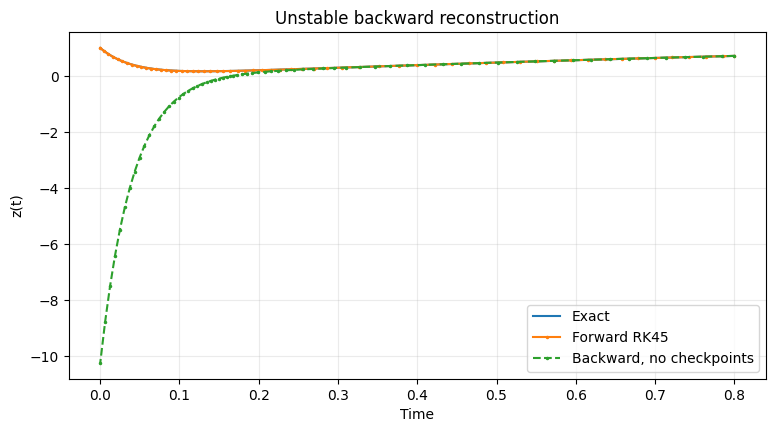

In [2]:
fw = integrate(0, T, 1.0)
bw = integrate(T, 0, fw.y[0, -1])

print(f"Exact z(T):           {exact(T):.10f}")
print(f"Numerical forward z(T): {fw.y[0, -1]:.10f}")
print(f"Recovered backward z(0): {bw.y[0, -1]:.6f} (true value: 1)")
print(f"Function evaluations: forward {fw.nfev}, backward {bw.nfev}")

t_dense = np.linspace(0, T, 500)
plt.figure(figsize=(9, 4.5))
plt.plot(t_dense, exact(t_dense), label='Exact')
plt.plot(fw.t, fw.y[0], '.-', markersize=3, label='Forward RK45')
plt.plot(bw.t, bw.y[0], '.--', markersize=3, label='Backward, no checkpoints')
plt.xlabel('Time'); plt.ylabel('z(t)'); plt.title('Unstable backward reconstruction')
plt.grid(alpha=.25); plt.legend(); plt.show()

## 3. Restart backward integration at saved forward checkpoints

For **K segments**, save the forward state at $K+1$ equally spaced times. On each segment $[t_j,t_{j+1}]$, start a backward solve from the **stored forward value** $z(t_{j+1})$ (not the end of the previous backward solve). This resets reconstruction error at every checkpoint.

We measure the **maximum mismatch at segment boundaries before resetting**. This measures reconstruction quality, not adjoint-gradient accuracy.

In [3]:
def reconstruct_with_checkpoints(K):
    ts = np.linspace(0, T, K + 1)
    forward_at_checkpoints = integrate(0, T, 1.0, t_eval=ts)
    saved = forward_at_checkpoints.y[0]
    parts = []
    mismatches = []
    nfe_backward = 0

    for j in range(K-1, -1, -1):
        backward_segment = integrate(ts[j+1], ts[j], saved[j+1])
        parts.append((backward_segment.t, backward_segment.y[0]))
        mismatches.append(abs(backward_segment.y[0,-1] - saved[j]))
        nfe_backward += backward_segment.nfev

    return dict(K=K, checkpoints=K+1, saved=ts.size,
                max_error=max(mismatches), backward_nfe=nfe_backward,
                forward_nfe=forward_at_checkpoints.nfev, parts=parts)

Ks = [1, 2, 4, 8, 16, 32]
results = [reconstruct_with_checkpoints(K) for K in Ks]

print(f"{'Segments':>9} {'Stored':>8} {'Max mismatch':>16} {'Backward NFE':>15}")
for r in results:
    print(f"{r['K']:9d} {r['saved']:8d} {r['max_error']:16.3e} {r['backward_nfe']:15d}")

 Segments   Stored     Max mismatch    Backward NFE
        1        2        1.123e+01             410
        2        3        5.099e-04             346
        4        5        3.425e-06             356
        8        9        3.061e-07             388
       16       17        8.224e-08             440
       32       33        3.881e-08             556


## 4. Accuracy and computational cost

The first plot compares reconstructed trajectories. The second shows the checkpoint **memory–accuracy–computation trade-off**: more checkpoints store more states and require separate backward solves.

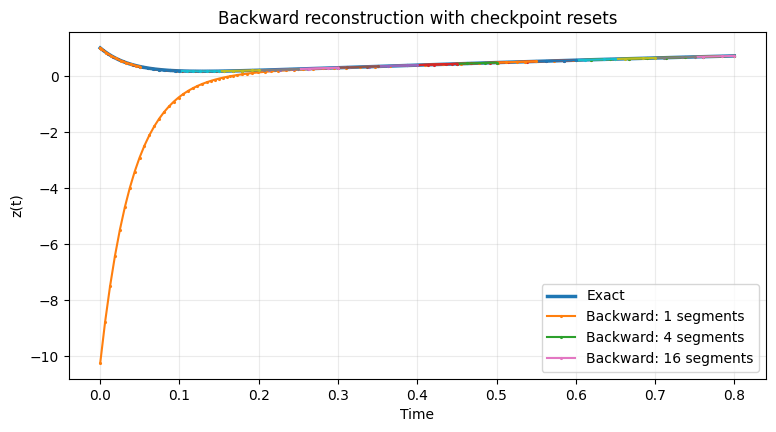

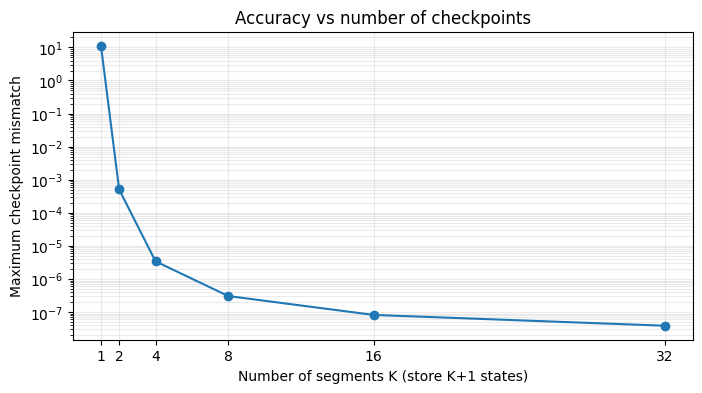

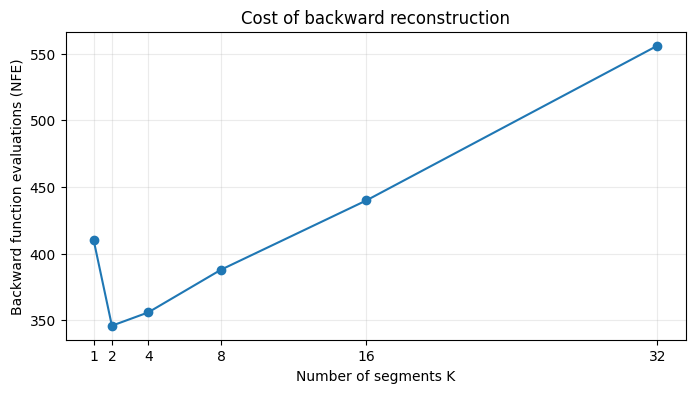

In [4]:
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(t_dense, exact(t_dense), linewidth=2.5, label='Exact')
for K in [1, 4, 16]:
    r = next(r for r in results if r['K'] == K)
    for i, (times, values) in enumerate(r['parts']):
        ax.plot(times, values, '.-', markersize=2.5,
                label=f'Backward: {K} segments' if i == 0 else None)
ax.set(xlabel='Time', ylabel='z(t)', title='Backward reconstruction with checkpoint resets')
ax.grid(alpha=.25); ax.legend(); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.semilogy(Ks, [r['max_error'] for r in results], 'o-')
ax.set(xlabel='Number of segments K (store K+1 states)',
       ylabel='Maximum checkpoint mismatch', title='Accuracy vs number of checkpoints')
ax.set_xticks(Ks); ax.grid(alpha=.25, which='both'); plt.show()

fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(Ks, [r['backward_nfe'] for r in results], 'o-')
ax.set(xlabel='Number of segments K', ylabel='Backward function evaluations (NFE)',
       title='Cost of backward reconstruction')
ax.set_xticks(Ks); ax.grid(alpha=.25); plt.show()

## Key takeaways

- The continuous solution is unique, but **backward numerical reconstruction** can be badly conditioned for forward-dissipative dynamics.
- Forward-state checkpoints can dramatically improve reconstruction by restarting over shorter intervals.
- Checkpointing trades **memory for stability**, and function-evaluation cost need not vary monotonically.
- **Important:** This demo restarts the *state* at checkpoints. In the full adjoint method, the adjoint and parameter-gradient accumulator continue across segments; only the reconstructed state is reset. Better state reconstruction often helps gradient accuracy, but this notebook **does not measure gradients**.
